In [2]:
#Generate random matching instance

import random
import math
from tqdm import tqdm
from generate_profiles import *


def generate_uniform(n):
    men_pref = []
    women_pref = []
    ordered = [i + 1 for i in range(n)]

    for i in range(n):
        mrand = ordered[:]
        random.shuffle(mrand)
        men_pref.append(mrand)

        wrand = ordered[:]
        random.shuffle(wrand)
        women_pref.append(wrand)

    return men_pref, women_pref


# https://immorlica.com/pubs/stablemarriage.pdf
def generate_preferences_with_popularity_distribution_over_men(n, distribution):
    men_pref = []
    women_pref = []
    ordered = [i + 1 for i in range(n)]

    for i in range(n):
        mrand = ordered[:]
        random.shuffle(mrand)
        men_pref.append(mrand)

    for i in range(n):
        w_list = []
        distribution_copy = distribution[:]
        ordered_copy = ordered[:]
        while len(w_list) != n:
            m = random.choices(ordered_copy, distribution_copy)[0]
            if m not in w_list:
                w_list.append(m)
                del distribution_copy[ordered_copy.index(m)]
                ordered_copy.remove(m)
        women_pref.append(w_list)

    return men_pref, women_pref


def generate_preferences_with_groups(n, group_sizes):
    men_pref = []
    women_pref = []
    ordered = [i + 1 for i in range(n)]
    random_agents_count = n - sum(group_sizes)
    random_agents = [i + 1 for i in range(random_agents_count)]
    group_agents = [i + 1 for i in range(random_agents_count, n)]
    groups = [random_agents]
    curr_agent = random_agents_count
    for size in group_sizes:
        groups.append([i + 1 for i in range(curr_agent, curr_agent + size)])
        curr_agent += size

    curr_group = 0
    for i in range(1, n + 1):
        # Update which group agent i is in if needed
        if i not in groups[curr_group]:
            curr_group += 1

        # If agent in random_agents
        if curr_group == 0:
            mrand = ordered[:]
            random.shuffle(mrand)
            men_pref.append(mrand)

            wrand = ordered[:]
            random.shuffle(wrand)
            women_pref.append(wrand)
        # If agent in group_agents
        else:
            mlist = groups[curr_group][:]
            random.shuffle(mlist)
            remaining_group_agents = list(set(group_agents) - set(groups[curr_group]))
            random.shuffle(remaining_group_agents)
            mlist += remaining_group_agents
            for agent in random_agents:
                mlist.insert(random.randrange(0, group_sizes[curr_group - 1] + 1), agent)
            men_pref.append(mlist)

            wlist = groups[curr_group][:]
            random.shuffle(wlist)
            remaining_group_agents = list(set(group_agents) - set(groups[curr_group]))
            random.shuffle(remaining_group_agents)
            wlist += remaining_group_agents
            for agent in random_agents:
                wlist.insert(random.randrange(0, group_sizes[curr_group - 1] + 1), agent)
            women_pref.append(wlist)

    return men_pref, women_pref


def generate_fixed_group_sizes_given_number_of_groups(n, g):
    if g == 0:
        return []
    group_sizes = [(n // g) for i in range(g)]
    index = 0
    while sum(group_sizes) != n:
        group_sizes[index] += 1
        index += 1
    return group_sizes


def generate_fixed_group_sizes_given_number_of_agents_per_group(n, g_size):
    group_sizes = [g_size for i in range(math.ceil(n / g_size))]
    index = 1
    while sum(group_sizes) != n:
        group_sizes[-index] -= 1
        index += 1
    return group_sizes


In [3]:
def mallows_prefs(size, phi):
    phis=[]
    phis.append(phi)
    cmap = gen_cand_map(size)
    refs = []
    refm, refc = gen_impartial_culture_strict(1, cmap);
    refs.append(io.rankmap_to_order(refm[0]))
    wrefs = []
    wrefm, wrefc = gen_impartial_culture_strict(1, cmap);
    wrefs.append(io.rankmap_to_order(wrefm[0]))
    mrmaps, mrmapscounts = gen_mallows(size, cmap, [1], phis, refs)
    wrmaps, wrmapscounts = gen_mallows(size, cmap, [1], phis, wrefs)
    men_profile = []
    women_profile = []

    for i,l in enumerate(mrmaps):
        order = [v for v in list(l.keys())]
        for j in range(mrmapscounts[i]):
            men_profile.append(order)

    for i,l in enumerate(wrmaps):
        order = [v for v in list(l.keys())]
        for j in range(wrmapscounts[i]):
            women_profile.append(order)
    
    return men_profile, women_profile



def mallows_prefs_two(size, phi1, phi2):
    phis1=[]
    phis1.append(phi1)
    phis2=[]
    phis2.append(phi2)
    cmap = gen_cand_map(size)
    refs = []
    refm, refc = gen_impartial_culture_strict(1, cmap);
    refs.append(io.rankmap_to_order(refm[0]))
    wrefs = []
    wrefm, wrefc = gen_impartial_culture_strict(1, cmap);
    wrefs.append(io.rankmap_to_order(wrefm[0]))
    mrmaps, mrmapscounts = gen_mallows(size, cmap, [1], phis1, refs)
    wrmaps, wrmapscounts = gen_mallows(size, cmap, [1], phis2, wrefs)
    men_profile = []
    women_profile = []

    for i,l in enumerate(mrmaps):
        order = [v for v in list(l.keys())]
        for j in range(mrmapscounts[i]):
            men_profile.append(order)

    for i,l in enumerate(wrmaps):
        order = [v for v in list(l.keys())]
        for j in range(wrmapscounts[i]):
            women_profile.append(order)
    
    return men_profile, women_profile


In [1]:
#Run Gale-Shapley

def gale_shapley(mpref, wpref, strategic_woman=0):
    n = len(mpref)
    curr_match_count = 0
    last_rejected_by_rank_what = [0 for i in range(n)]
    men_matchings = [0 for i in range(n)]
    women_matchings = [0 for i in range(n)]
    proposals_to_strategic_woman = set()    # Only used if strategic_woman != 0

    # continue until all matches made
    while curr_match_count < n:
        for man in range(n):
            # if man is single
            if men_matchings[man] == 0:
                # get first non-rejecting woman from man's preference list
                woman = mpref[man][last_rejected_by_rank_what[man]] - 1
                if woman + 1 == strategic_woman:
                    proposals_to_strategic_woman.add(man + 1)

                # both man and woman are single
                if women_matchings[woman] == 0:
                    # create match (man, woman)
                    men_matchings[man] = woman + 1
                    women_matchings[woman] = man + 1
                    curr_match_count += 1

                # woman is with someone
                else:
                    # find ranks of curr_partner and man given woman's preference list
                    curr_partner = women_matchings[woman]
                    print(type(wpref[woman]))
                    curr_partner_rank = wpref[woman].index(curr_partner)
                    man_rank = wpref[woman].index(man + 1)

                    # woman prefers curr_partner over man
                    if curr_partner_rank < man_rank:
                        last_rejected_by_rank_what[man] = mpref[man].index(woman + 1) + 1

                    # woman prefers man over curr_partner
                    else:
                        men_matchings[curr_partner - 1] = 0
                        last_rejected_by_rank_what[curr_partner - 1] = mpref[curr_partner - 1].index(woman + 1) + 1
                        men_matchings[man] = woman + 1
                        women_matchings[woman] = man + 1

    if strategic_woman != 0:
        return men_matchings, proposals_to_strategic_woman
    else:
        return men_matchings

def get_m_partner(m, matches):
    return matches[m - 1]


def get_w_partner(w, matches):
    return matches.index(w) + 1


def get_m_rank(m, mpref, matches):
    partner = matches[m - 1]
    return mpref[m - 1].index(partner) + 1


def get_w_rank(w, wpref, matches):
    partner = matches.index(w) + 1
    return wpref[w - 1].index(partner) + 1


# Checks if matching1 Pareto-improves matching2 for the set of all women
def pareto_improvement_women(wpref, matching1, matching2):
    n = len(matching1)
    matching1_ranks = [get_w_rank(w, wpref, matching1) for w in range(1, n + 1)]
    matching2_ranks = [get_w_rank(w, wpref, matching2) for w in range(1, n + 1)]
    ranks_difference = [matching2_ranks[i] - matching1_ranks[i] for i in range(n)]
    improvement = False
    for diff in ranks_difference:
        if diff < 0:
            return False
        if diff > 0:
            improvement = True
    return improvement


def check_stability(mpref, wpref, matching, return_blocking_pairs=False):
    n = len(mpref)
    blocking_pairs = []

    for m in range(1, n + 1):
        m_partner = matching[m - 1]
        rank_of_m_partner = mpref[m - 1].index(m_partner) + 1
        for w in range(1, n + 1):
            w_partner = matching.index(w) + 1
            rank_of_w_partner = wpref[w - 1].index(w_partner) + 1

            # if (m, w) is not a matching
            if matching[m - 1] != w:
                rank_of_w_for_m = mpref[m - 1].index(w) + 1
                rank_of_m_for_w = wpref[w - 1].index(m) + 1
                if rank_of_m_partner > rank_of_w_for_m and rank_of_w_partner > rank_of_m_for_w:
                    if return_blocking_pairs:
                        bp = (m, w)
                        blocking_pairs.append(bp)
                    else:
                        return False

    if return_blocking_pairs:
        return blocking_pairs
    else:
        return True

In [5]:
def self_manipulation(mpref, wpref, manipulator, return_all_strategies=False):
    n = len(mpref)

    # initial run of gale_shapley
    gs_matching, all_proposers = gale_shapley(mpref, wpref, manipulator)
    #print(gale_shapley(mpref, wpref, manipulator))
    exhausted_proposers = [get_w_partner(manipulator, gs_matching)]

    proposer_dict = {}  # key = proposer; value = manipulated  preference list
    strategy = (gs_matching, wpref[manipulator - 1][:])
    all_strategies = [strategy]

    # update proposer_dict to include all proposers from the initial run
    for proposer in all_proposers:
        proposer_dict.update({proposer: wpref[manipulator - 1][:]})

    # loop until all potential proposers are exhausted
    while len(exhausted_proposers) != len(all_proposers):
        all_proposers_copy = all_proposers.copy()

        # for all proposers that haven't been exhausted
        for proposer in all_proposers:
            if proposer not in exhausted_proposers:
                # create a new manipulated list with proposer in front
                new_list = proposer_dict[proposer]
                new_list.remove(proposer)
                new_list.insert(0, proposer)
                exhausted_proposers.append(proposer)

                # update each non-exhausted proposer's list in proposer_dict
                for prop in proposer_dict:
                    if prop not in exhausted_proposers:
                        proposer_dict.update({proposer: new_list[:]})

                # run gale_shapley using the new manipulated list
                wpref_new = wpref[:]
                wpref_new[manipulator - 1] = new_list
                new_matching, new_proposers = gale_shapley(mpref, wpref_new, manipulator)
                all_proposers_copy = all_proposers_copy.union(new_proposers)
                strategy = (new_matching[:], new_list[:])
                all_strategies.append(strategy)

                # update proposer_dict to include any new proposers
                for prop in all_proposers_copy:
                    if prop not in exhausted_proposers and prop not in proposer_dict:
                        proposer_dict.update({prop: wpref_new[manipulator - 1][:]})

        # update all_proposers
        all_proposers = all_proposers_copy

    if return_all_strategies:
        return all_strategies

    # find cheater's best ranking man from all those who proposed
    best_man_rank = n + 1
    best_strategy = None
    for strategy in all_strategies:
        rank = get_w_rank(manipulator, wpref, strategy[0])
        if rank < best_man_rank:
            best_man_rank = rank
            best_strategy = strategy

    return best_strategy


In [17]:
number = []

n=30
phi_list=[0, 0.2, 0.4, 0.6, 0.8, 1]

for phi1 in tqdm(phi_list):
    number_phi = []
    for phi2 in tqdm(phi_list):
        count =[]
        ct=[]
        for samples in range (500):
            cnt=0
            pref=mallows_prefs_two(n, phi1, phi2)
            mpref=pref[0]
            wpref=pref[1]
            for manipulator in range (1, n+1):
                matching = gale_shapley(mpref, wpref)
                result = self_manipulation(mpref, wpref, manipulator)
                if result [0]!= matching:
                    cnt = cnt+1
            count.append(cnt)
        #number_phi.append(sum(count) / len(count))
        if len(count)>0:
            number_phi.append(sum(count) / len(count))
        else:
            number_phi.append(0)
    number.append(number_phi)
print(number)          

  0%|          | 0/6 [00:04<?, ?it/s]


KeyboardInterrupt: 

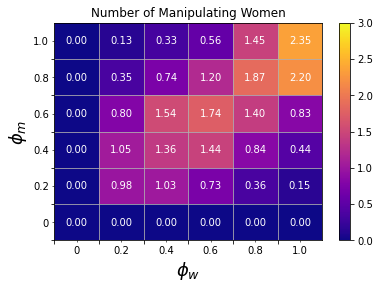

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

phis = [0, 0.2, 0.4, 0.6, 0.8, 1.0]
 
    
w_number = np.array(number)
# Create the pcolormesh plot

fig, ax = plt.subplots()

c = ax.pcolormesh(w_number, cmap='plasma', norm=mcolors.Normalize(vmin=0, vmax=3))
 
# Add color bar

fig.colorbar(c, ax=ax)
 
# Annotate each cell with the numeric value

for i in range(w_number.shape[0]):

    for j in range(w_number.shape[1]):

        ax.text(j + 0.5, i + 0.5, f'{w_number[i, j]:.2f}', 

                ha='center', va='center', color='white')
        

ax.set_xticks(np.arange(w_number.shape[1]))
ax.set_yticks(np.arange(w_number.shape[0]))

# Manually set the tick labels to be centered within each cell
ax.set_xticks(np.arange(w_number.shape[1]) + 0.5, minor=True)
ax.set_yticks(np.arange(w_number.shape[0]) + 0.5, minor=True)
ax.set_xticklabels(phis, minor=True)
ax.set_yticklabels(phis, minor=True)

# Hide the major tick labels
ax.set_xticklabels([], minor=False)
ax.set_yticklabels([], minor=False)

# Show minor ticks
ax.tick_params(axis='x', which='minor', bottom=True, top=False)
ax.tick_params(axis='y', which='minor', left=True, right=False)

plt.xlabel('$\phi_w$', fontsize=18)
plt.ylabel('$\phi_m$', fontsize=18)
plt.title('Number of Manipulating Women')
plt.grid(True)

plt.savefig("number_of_manipulators_Mallows", format='pdf')
plt.show()        

In [13]:
number = []

n=30
phi_list=[0, 0.2, 0.4, 0.6, 0.8, 1]

for phi1 in tqdm(phi_list):
    number_phi = []
    for phi2 in tqdm(phi_list):
        count =[]
        ct=[]
        for samples in range (100):
            cnt=0
            pref=mallows_prefs_two(n, phi1, phi2)
            mpref=pref[0]
            wpref=pref[1]
            for manipulator in range (1, n+1):
                matching = gale_shapley(mpref, wpref)
                result = self_manipulation(mpref, wpref, manipulator)
                if result [0]!= matching:
                    cnt = cnt+1
            count.append(cnt)
        #number_phi.append(sum(count) / len(count))
        if len(count)>0:
            number_phi.append(max(count))
        else:
            number_phi.append(0)
    number.append(number_phi)
print(number)          

100%|███████████████████████████████████████████████████████████████████████████████████| 6/6 [19:15<00:00, 192.66s/it]

[[0, 0, 0, 0, 0, 0], [0, 6, 7, 4, 4, 2], [0, 4, 9, 10, 5, 5], [0, 5, 8, 9, 6, 5], [0, 3, 7, 9, 12, 7], [0, 2, 4, 4, 7, 17]]


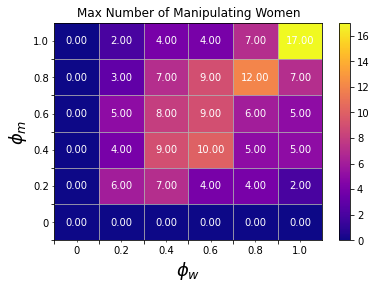

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

phis = [0, 0.2, 0.4, 0.6, 0.8, 1.0]
 
    
w_number = np.array(number)
# Create the pcolormesh plot

fig, ax = plt.subplots()

c = ax.pcolormesh(w_number, cmap='plasma', norm=mcolors.Normalize(vmin=0, vmax=17))
 
# Add color bar

fig.colorbar(c, ax=ax)
 
# Annotate each cell with the numeric value

for i in range(w_number.shape[0]):

    for j in range(w_number.shape[1]):

        ax.text(j + 0.5, i + 0.5, f'{w_number[i, j]:.2f}', 

                ha='center', va='center', color='white')
        

ax.set_xticks(np.arange(w_number.shape[1]))
ax.set_yticks(np.arange(w_number.shape[0]))

# Manually set the tick labels to be centered within each cell
ax.set_xticks(np.arange(w_number.shape[1]) + 0.5, minor=True)
ax.set_yticks(np.arange(w_number.shape[0]) + 0.5, minor=True)
ax.set_xticklabels(phis, minor=True)
ax.set_yticklabels(phis, minor=True)

# Hide the major tick labels
ax.set_xticklabels([], minor=False)
ax.set_yticklabels([], minor=False)

# Show minor ticks
ax.tick_params(axis='x', which='minor', bottom=True, top=False)
ax.tick_params(axis='y', which='minor', left=True, right=False)

plt.xlabel('$\phi_w$', fontsize=18)
plt.ylabel('$\phi_m$', fontsize=18)
plt.title('Max Number of Manipulating Women')
plt.grid(True)

plt.savefig("max_number_of_manipulators_Mallows", format='pdf')
plt.show()        

In [16]:
results1 = mallows_prefs(4, 0)
print(results1)

print(self_manipulation(results1[0], results1[1], 3))

print(' ')

results2 = mallows_prefs(4, 0.2)
#print(results2)

print(self_manipulation(results2[0], results2[1], 3))

print(' ')

results3 = mallows_prefs(4, 0.4)
#print(results3)

print(self_manipulation(results3[0], results3[1], 3))

print(' ')

results4 = mallows_prefs(4, 0.6)
#print(results4)

print(self_manipulation(results4[0], results4[1], 3))

print(' ')

results5 = mallows_prefs(4, 0.8)
#print(results5)

print(self_manipulation(results5[0], results5[1], 3))

print(' ')

results6 = mallows_prefs(4, 1)
#print(results6)

print(self_manipulation(results6[0], results6[1], 3))



([[3, 4, 2, 1], [3, 4, 2, 1], [3, 4, 2, 1], [3, 4, 2, 1]], [[1, 2, 3, 4], [1, 2, 3, 4], [1, 2, 3, 4], [1, 2, 3, 4]])
([3, 4, 2, 1], [1, 2, 3, 4])
 
([2, 4, 1, 3], [2, 4, 1, 3])
 
([1, 2, 3, 4], [2, 1, 4, 3])
 
([2, 4, 1, 3], [1, 4, 3, 2])
 
([1, 4, 2, 3], [2, 4, 1, 3])
 
([4, 3, 2, 1], [3, 1, 2, 4])
